# 로봇용접 공정이상 탐지 — 핵심 결과 요약

이 노트북은 **분석을 수행하지 않는다.** `bash run_all.sh` 가 만든 `outputs/` 를
읽어 핵심 수치와 그림만 모아 보여준다. 전체 재현은 약 150분이 걸리므로,
결과만 빠르게 확인하려는 사람을 위한 진입점이다.

| | |
|---|---|
| 데이터 | 용접점 11,939개 / 불량 라벨 작업일 집계 39건 (8일) |
| 핵심 제약 | 설명변수와 라벨의 **관측단위가 다르다** |
| 원본 데이터 | 저장소에 없음 → `data/raw/README.md` (이 노트북은 데이터 없이 동작) |

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"

def table(name, **kw):
    """산출물 csv 를 읽는다. 모든 수치의 단일 출처."""
    return pd.read_csv(TAB / name, encoding="utf-8-sig", **kw)

def figure(name, width=760):
    display(Image(filename=str(FIG / name), width=width))

print("표", len(list(TAB.glob("*.csv"))), "종 / 그림", len(list(FIG.glob("*.png"))), "종")

표 106 종 / 그림 41 종


---
## 1. 라벨과 설명변수의 관측단위가 다르다

두 데이터를 용접점별로 연결할 키가 없다. **용접점 단위 지도학습의 정답이 존재하지 않는다.**

,항목,값,분석상 의미
0,Raw data 용접점 수,"11,939",설명변수는 충분
1,불량 라벨 총 건수,39 건,극소수
2,라벨이 부여된 관측단위,작업일 (용접점 아님),용접점 단위 지도학습 불가
3,라벨 유효 표본 수,8 일,복잡한 모델 적용 불가 / 검정력 부재
4,설비 종류,1 종 (Spot-01),설비 간 비교 불가
5,품목 종류,1 종 (65235-25800),품목 간 비교 불가
6,소재 두께 고유값,"1 개 (0.7mm 고정, 분산 0)",두께를 설명변수로 쓸 수 없음
7,working time 해상도,날짜 (시:분 없음),작업일 내 시간분해 불가
8,라벨 없는 작업일,"2020-03-27 (1,648 점) -> 예측 대상",테스트데이터 예측결과로 제출


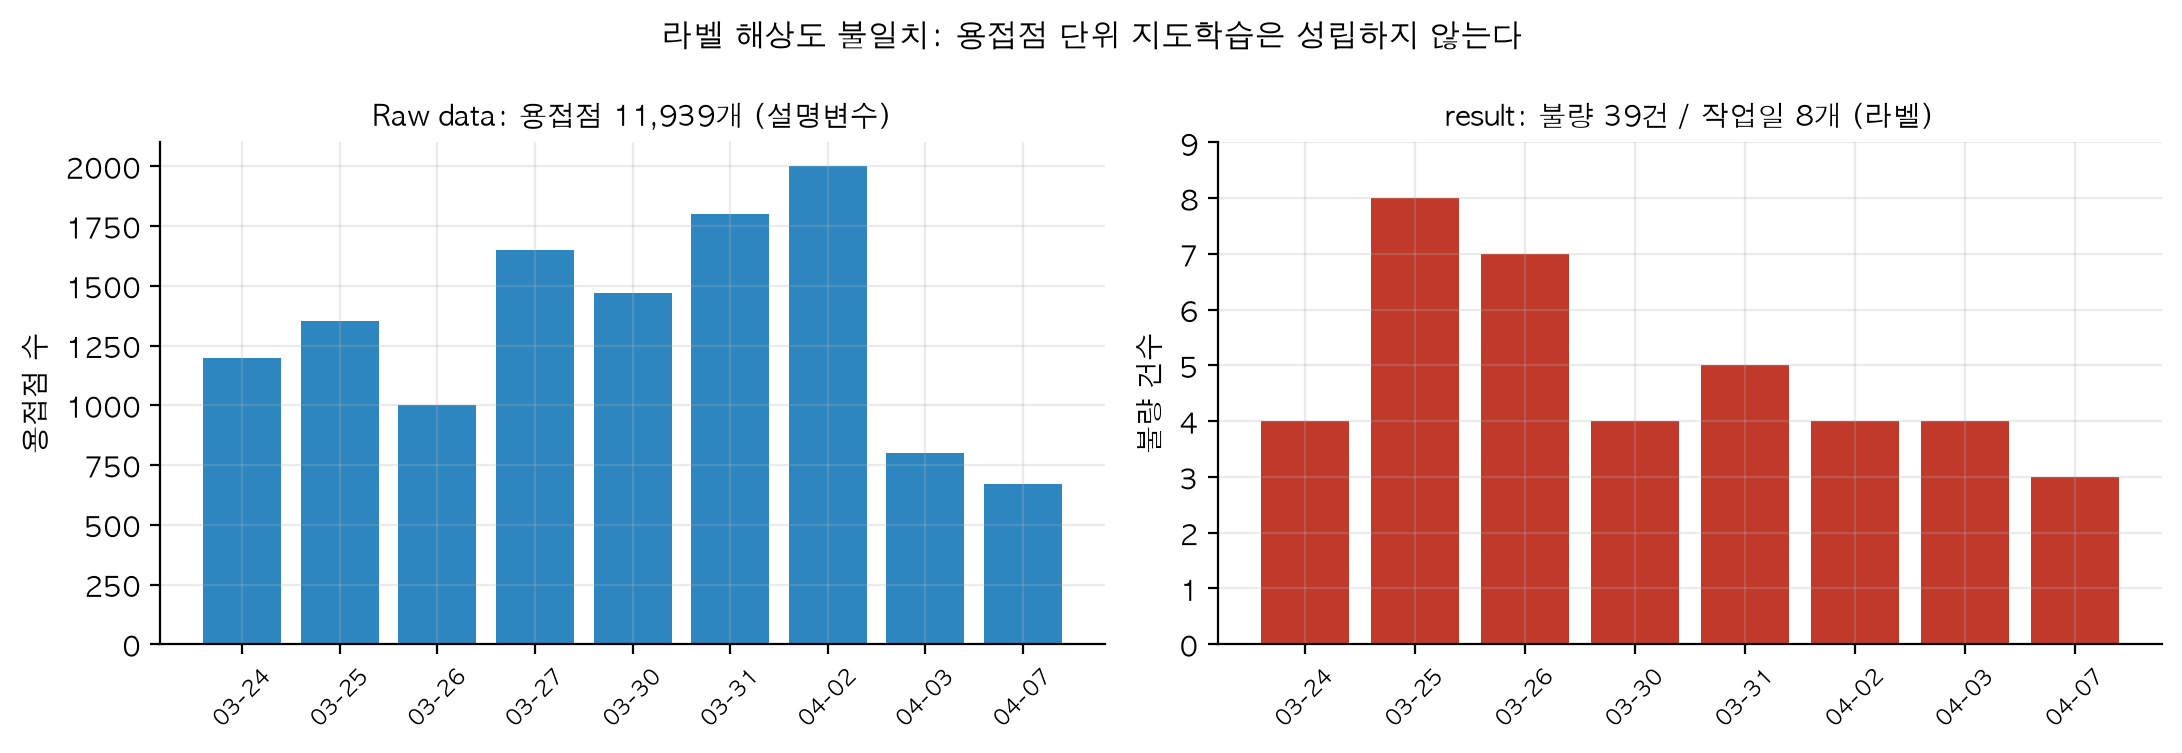

In [2]:
display(table("t2_label_reality.csv"))
figure("f3_label_resolution.png")

---
## 2. 전체의 26.8%가 복제된 구간이다

공정 4변수의 미세값까지 연속 800점이 일치하는 구간을 **사전 임계값 없이** 탐색했다.
행 지문(해시) + 최장 연속일치 방식이다.

,관측 사실,값
0,연속 일치 구간 길이,800 점 (사전 기준 없이 탐색)
1,반복된 작업일 수,4 일
2,전체 데이터 대비 비중,"3,200 / 11,939 점 = 26.8%"
3,구간 내 가압력 분포,3bar 이하 509점 / 초과 291점
4,삽입 위치 (idx 시작),"271, 735, 725, 1"
5,작업일 전체가 복제 구간인 날,2020-04-03
6,구간 밖 반증 대조,전 쌍 불일치 — 복제가 이 구간에 한정
7,일치의 정밀도,전류 0.01kA·전압 0.001V 미세값까지 동일
8,판정,실제 공정변동이 아니라 복제된 동일 레코드
9,초판 대비 정정,가압력 3bar 기준으로는 291점만 포착되어 복제 범위를 36% 로 과소평가했다


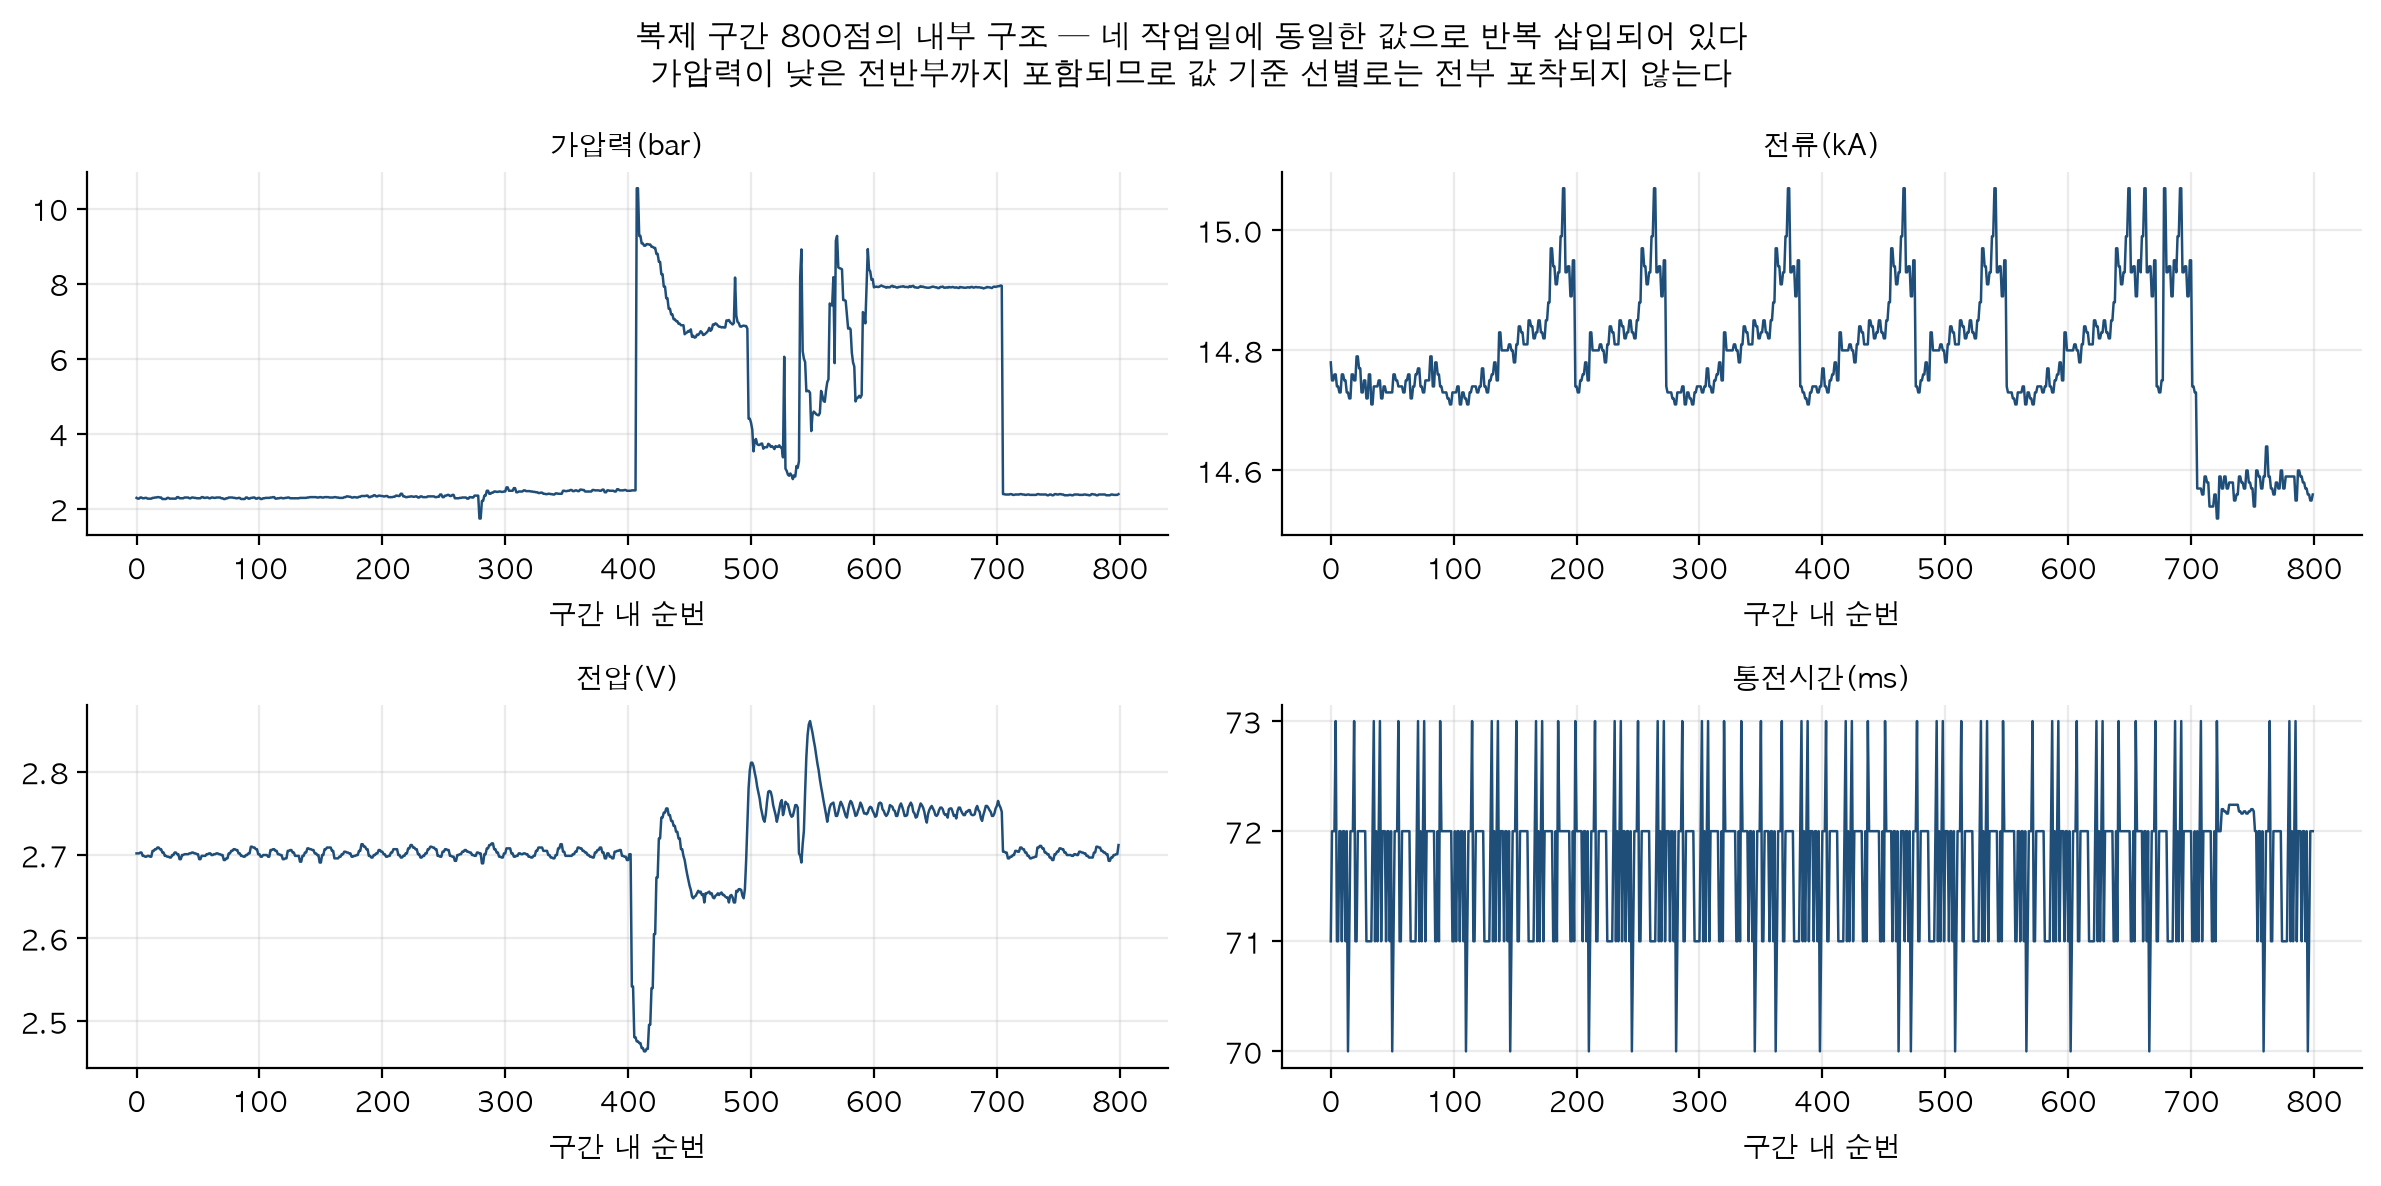

In [3]:
display(table("t21_integrity_verdict.csv"))
figure("f11_duplicated_block.png")

---
## 3. 높은 성능은 분할 설계에서 나온다

작업일 라벨을 용접점에 전가해 이진분류를 **실제로 수행**했다.
행 무작위 분할의 0.586은 판별력이 아니라 **같은 작업일 행이 학습·평가에 함께 들어간 누수**다.

,라벨 생성 방식,양성 비율(%),분할 방식,ROC-AUC,PR-AUC,라벨셔플 ROC-AUC,셔플 대비 초과
0,방식 A (건수 전가),0.38,행 무작위 분할,0.511,0.0063,0.548,-0.037
1,방식 A (건수 전가),0.38,작업일 그룹 분할,0.535,0.0065,0.575,-0.040
2,방식 B (일자 전가),40.35,행 무작위 분할,0.586,0.4581,0.509,0.076
3,방식 B (일자 전가),40.35,작업일 그룹 분할,0.305,0.4338,0.505,-0.199


,검증,ROC-AUC,순열 p,해석
0,방식 B · 행 무작위 분할,0.586,0.038,같은 작업일의 행이 학습·평가에 동시에 들어가 작업일을 암기한다
1,방식 B · 작업일 그룹 분할,0.305,1.000,미지의 작업일에는 일반화되지 않는다. 판별력의 실체가 없다


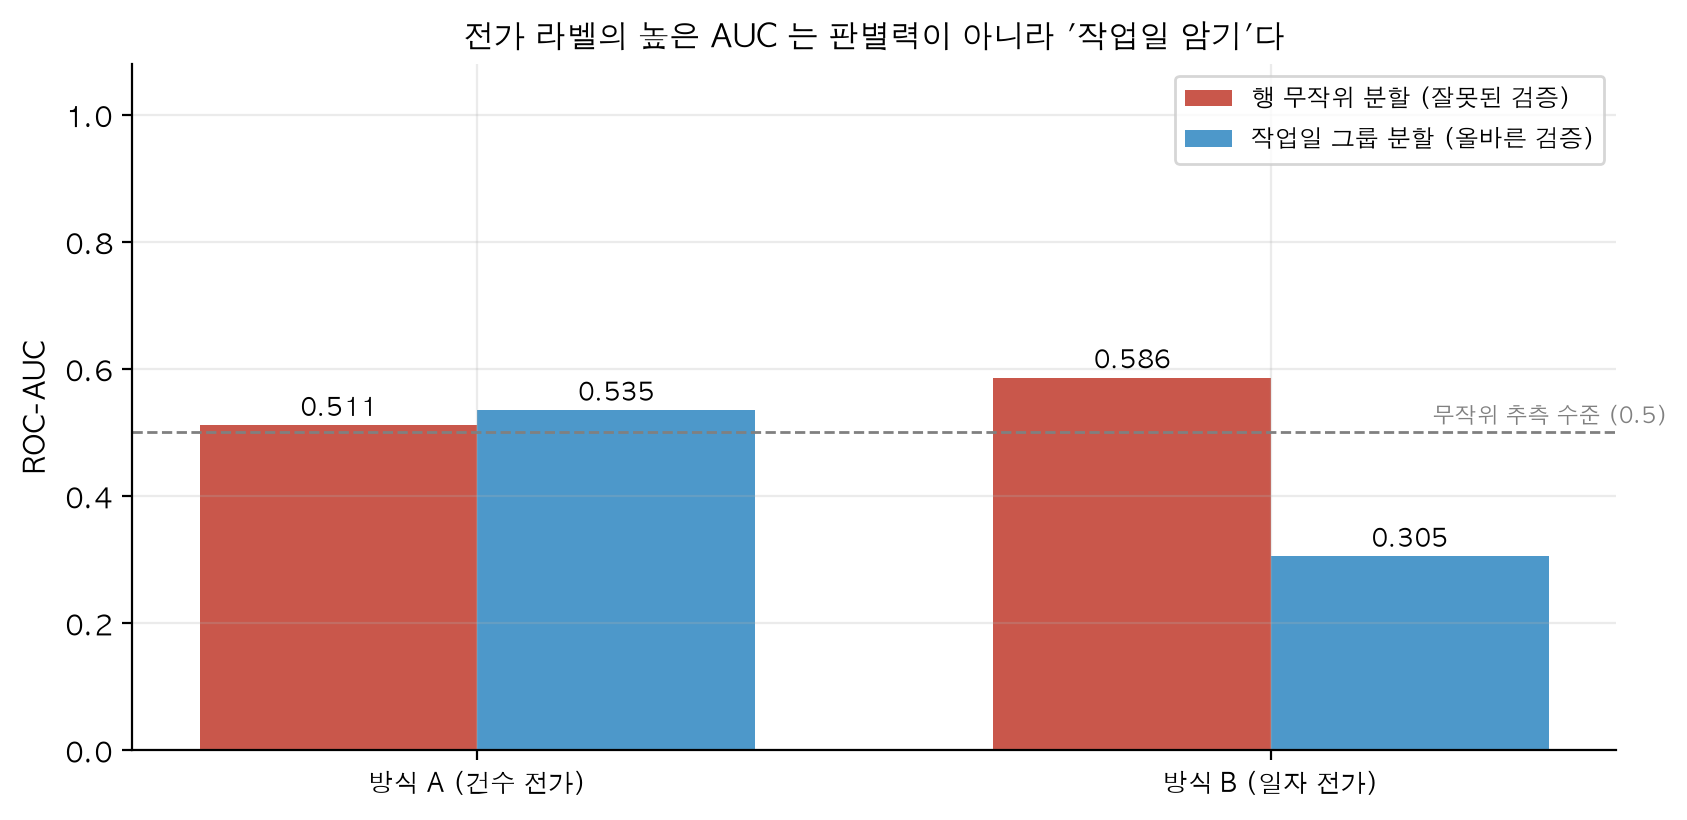

In [4]:
display(table("t13_naive_binary_contrast.csv"))
display(table("t14_naive_conclusion.csv"))
figure("f7_naive_contrast.png")

---
## 4. 모델 비교 — 11모형 × 3특징공간 × 6개 합성 이상유형

평균이 높고 특정 고장유형에서 무너지는 모형을 피하려고 **최악 유형 ROC-AUC 가 가장 높은**
조합을 택했다(최소최대 기준, 사전 고정).

특징공간별


,특징공간,ROC-AUC,최악 유형 평균
0,FS1 가압력·전류,0.733,0.499
1,FS2 원 4변수,0.794,0.686
2,FS3 물리 파생,0.799,0.680



모형 × 이상유형 (FS3)


,모형,A1 결합이탈,A2 가압이탈,A3 전압강하,A4 통전단축,A5 동시드리프트,A6 산포증가,평균,최악
0,M0 단변량(가압력),0.503,0.979,0.489,0.488,0.856,0.733,0.675,0.488
1,M1 단변량(전류),0.639,0.494,0.495,0.505,0.761,0.701,0.599,0.494
2,M2 Hotelling T2,0.879,0.976,0.607,0.800,0.797,0.872,0.822,0.607
3,M3 마할라노비스(MCD),0.905,0.983,0.598,0.793,0.797,0.878,0.826,0.598
4,M4 PCA 재구성오차,0.926,0.917,0.618,0.575,0.546,0.832,0.736,0.546
5,M5 Isolation Forest,0.828,0.920,0.664,0.801,0.838,0.878,0.822,0.664
6,M6 LOF,0.864,0.917,0.808,0.714,0.890,0.892,0.848,0.714
7,M7 One-Class SVM,0.902,0.934,0.610,0.530,0.798,0.872,0.774,0.530
8,M8 kNN 거리,0.949,0.987,0.892,0.904,0.941,0.964,0.940,0.892
9,M9 정상운전모델 잔차,0.926,0.776,0.883,0.795,0.897,0.915,0.865,0.776


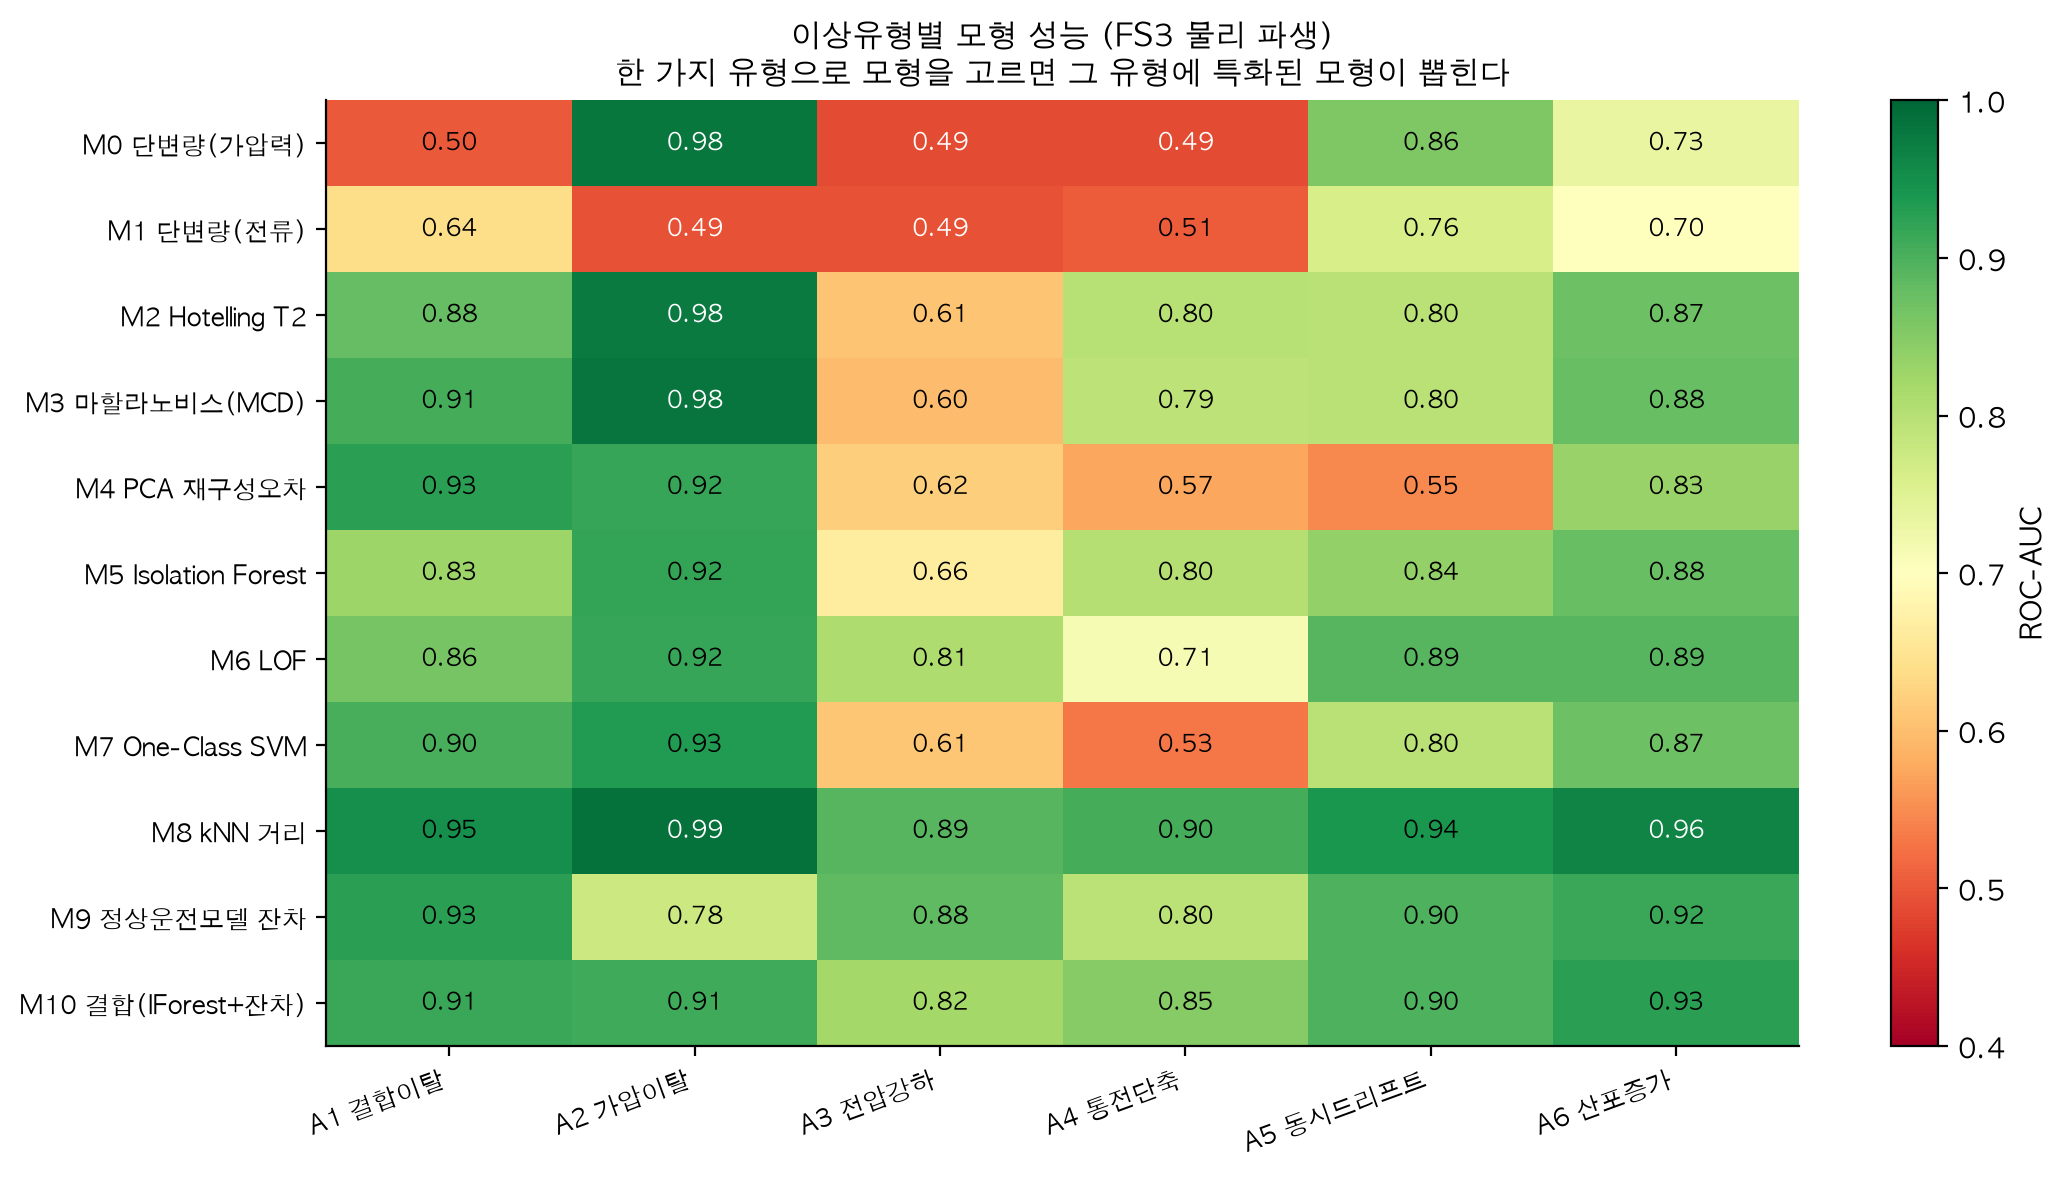

In [5]:
print("특징공간별"); display(table("t35_by_featurespace.csv"))
print("\n모형 × 이상유형 (FS3)"); display(table("t36_model_by_anomtype.csv"))
figure("f22_benchmark_heatmap.png")

### 초모수는 중첩 교차검증으로 선택했다

바깥 폴드는 성능평가에만 쓰고 안쪽 폴드에서 k 를 정했다. **5개 바깥 폴드 전부 k=3** 을
선택했고, 편향 없는 바깥 성능은 최악 유형 ROC-AUC 평균 0.937 이다.

In [6]:
display(table("t50_nested_k.csv"))

,평가일(바깥),선택된 k,안쪽 최악 AUC,바깥 최악 AUC
0,2020-03-24,3,0.919,0.780
1,2020-03-26,3,0.931,1.000
2,2020-03-30,3,0.940,1.000
3,2020-04-02,3,0.882,0.903
4,2020-04-07,3,0.937,1.000


---
## 5. 최종 성능 — 검증 근거를 구분해서 읽는다

> **0.971 은 실제 불량 탐지율이 아니다.** 본 연구가 설계·주입한 합성 고장모드 7종에 대한
> 민감도다. 실제 불량 39건과의 연결은 **검정 가능한 5종 전부 비유의**(최소 순열 p 0.651)였다.

이상 강도별 7유형 성능  〔합성 이상〕


,이상유형,1.0,1.5,2.0,3.0,평균
0,A1 결합이탈,0.975,0.977,0.981,0.992,0.981
1,A2 가압이탈,0.972,0.978,0.989,0.993,0.983
2,A3 전압강하,0.941,0.951,0.957,0.971,0.955
3,A4 통전단축,0.971,0.948,0.965,0.979,0.966
4,A5 동시드리프트,0.971,0.972,0.975,0.981,0.975
5,A6 산포증가,0.972,0.979,0.984,0.991,0.982
6,A7 지속반복이상,0.965,0.918,0.936,0.995,0.954


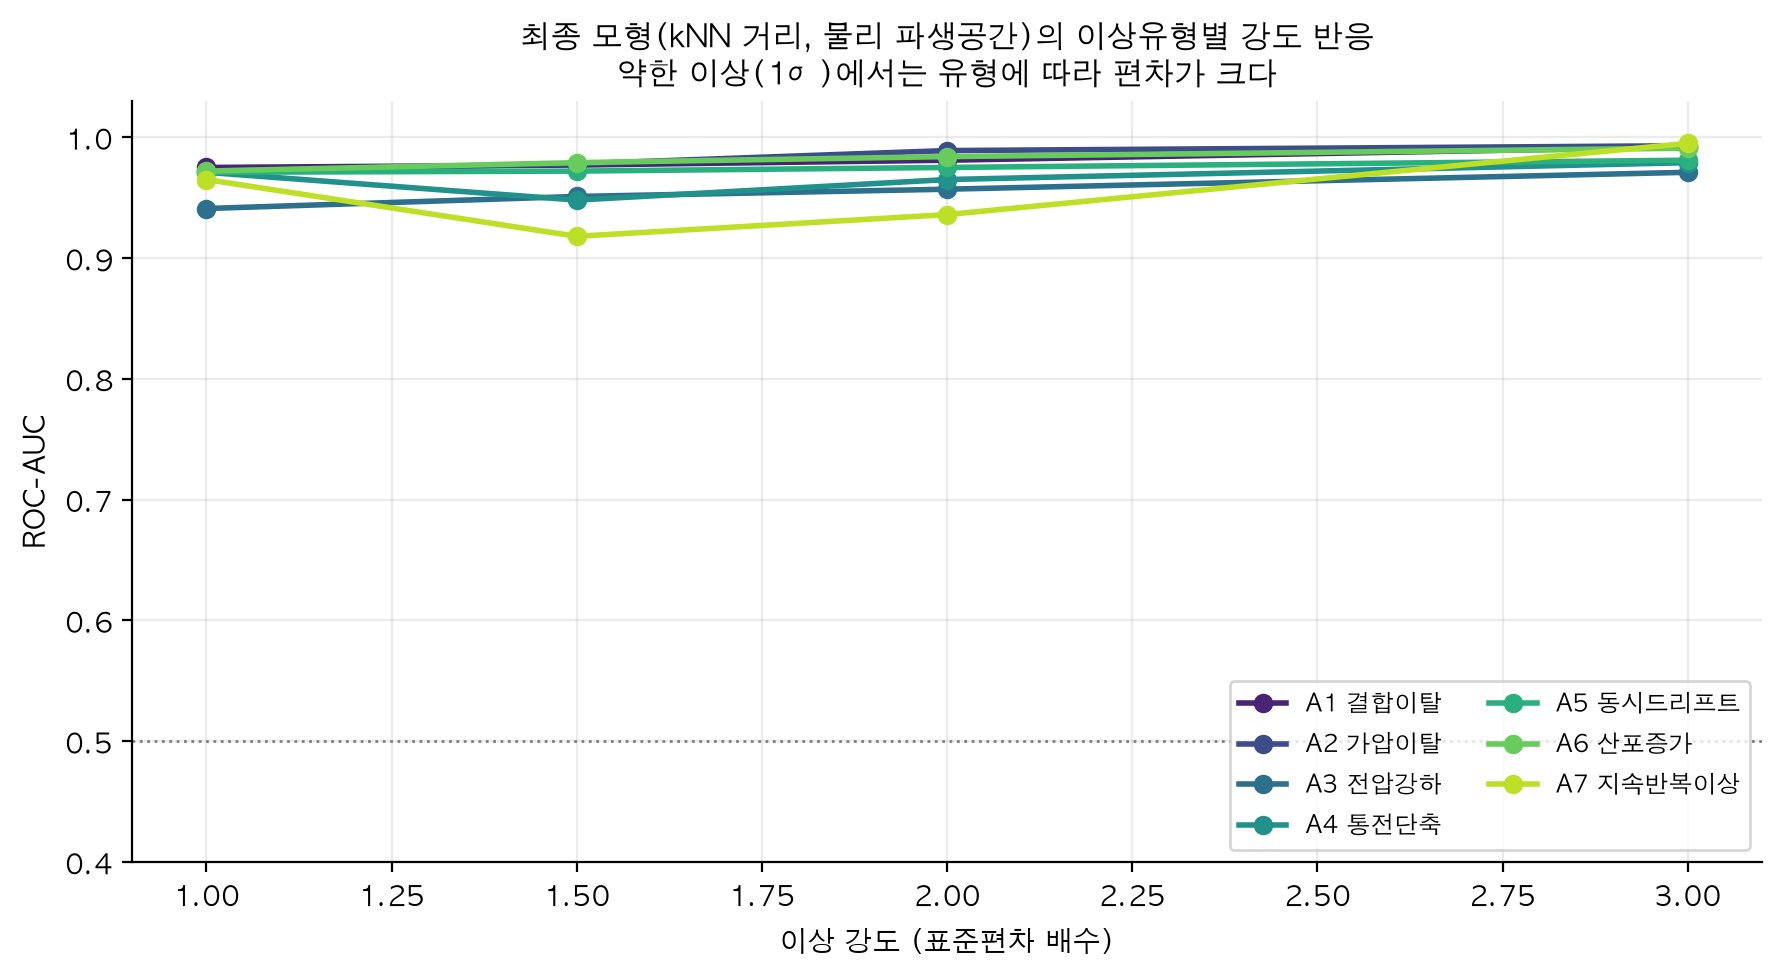

In [7]:
print("이상 강도별 7유형 성능  〔합성 이상〕"); display(table("t41_severity_sweep.csv"))
figure("f25_severity_sweep.png")

In [8]:
print("외부 실제라벨 데이터에 튜닝 없이 적용  〔외부 실제라벨〕")
try:
    display(table("t78_external_model_ranking.csv"))
except FileNotFoundError:
    print("  부록 A 산출물 — 외부 데이터가 없어 생성되지 않았다 (정상)")

외부 실제라벨 데이터에 튜닝 없이 적용  〔외부 실제라벨〕


,모형,ROC-AUC,PR-AUC
0,M8 kNN 거리 (용접기 최종 선정),0.899,0.742
1,M5 Isolation Forest,0.897,0.690
2,M6 LOF,0.892,0.750
3,M2 Hotelling T2,0.887,0.713
4,M3 마할라노비스(MCD),0.885,0.706
5,M0 단변량(AI1_Vibration),0.838,0.574
6,M0 단변량(AI0_Vibration),0.797,0.606
7,M7 One-Class SVM,0.616,0.550
8,M0 단변량(AI2_Current),0.577,0.338


---
## 6. 작업일 불량건수 예측 — 제출한 예측결과

공정조건을 넣은 모형이 **모두 기준선보다 나빴다.** 이는 성과가 아니라
현재 8일 표본에서 그 관계를 검출하지 못했다는 **진단 결과**다.

In [9]:
print("모델 비교"); display(table("t22_taskA_model_comparison.csv"))
print("\n테스트일 예측 (제출물)")
display(pd.read_csv(ROOT / "outputs" / "prediction_20200327.csv", encoding="utf-8-sig"))

모델 비교


,모형,LOO-MAE,LOO-RMSE,AIC,95% 구간 포함률(%),기준선 대비 MAE
0,M0 기준선 (절편 전용),1.536,1.846,33.28,100.0,—
1,M1 비례 (offset = 용접점수),2.190,2.582,36.33,100.0,+42.6%
2,M2 Poisson GLM (+전류_표준편차),1.712,2.216,34.49,100.0,+11.5%
3,M3 음이항 GLM (+전류_표준편차),1.708,2.215,46.75,100.0,+11.2%



테스트일 예측 (제출물)


,working_time,Machine_Name,Item_No,n_welds,pred_defect_count,pred_lower_95_poisson,pred_upper_95_poisson,pred_lower_889_jackknife_plus,pred_upper_889_jackknife_plus
0,2020-03-27,Spot-01,65235-25800,1648,4.88,1,10,0.86,8.0


---
## 7. 일 단위 공정 이동 경보 — 현장 권고

정교한 용접점 순차감시(kNN + 컨포멀 + CUSUM)는 **0/3**, 고전적 관리도는 **3/3** 탐지했다.
본 데이터의 실제 이상이 개별 점의 국소 이탈이 아니라 **하루 전체의 수준 이동**이기 때문이다.

⚠️ 탐지된 3일 중 하나(03-27)는 **불량 라벨이 없는 예측대상일**이다.
이 경보는 **공정 이동**을 탐지하며 불량 발생을 탐지한다는 근거는 없다.

일 단위 관리도


,변수,통계량,관리한계,이상일 탐지,안정일 오경보,유효
0,가압력,중앙값,2 sigma,3/3,0/5,예
1,가압력,중앙값,2.5 sigma,3/3,0/5,예
2,가압력,중앙값,3 sigma,0/3,0/5,아니오
3,가압력,평균,2 sigma,2/3,0/5,예
4,가압력,평균,2.5 sigma,1/3,0/5,예
5,가압력,평균,3 sigma,0/3,0/5,아니오
6,전류,중앙값,2 sigma,0/3,0/5,아니오
7,전류,중앙값,2.5 sigma,0/3,0/5,아니오
8,전류,중앙값,3 sigma,0/3,0/5,아니오
9,전류,평균,2 sigma,1/3,0/5,예



평가 대상 작업일의 정체


,작업일,원본 용접점,복제 제외 후,가압력 중앙값,불량건수,역할
0,2020-03-24,1200,1200,2.33,4,안정일 — 관리한계 추정에 사용
1,2020-03-25,1352,552,2.31,8,이상일 — 탐지 평가 대상
2,2020-03-26,1000,1000,2.35,7,안정일 — 관리한계 추정에 사용
3,2020-03-27,1648,848,2.31,없음(예측대상),이상일 — 탐지 평가 대상 (※ 불량 라벨 없는 예측대상일)
4,2020-03-30,1470,1470,2.35,4,안정일 — 관리한계 추정에 사용
5,2020-03-31,1800,1000,2.31,5,이상일 — 탐지 평가 대상
6,2020-04-02,2000,2000,2.33,4,안정일 — 관리한계 추정에 사용
7,2020-04-03,800,0,NaN,4,제외 — 작업일 전체가 복제 구간
8,2020-04-07,669,669,2.35,3,안정일 — 관리한계 추정에 사용



작업일 단위 정확 순열검정


,항목,값
0,분석단위,작업일 (안정 5일 vs 이상 3일)
1,검정 통계량,일별 가압력 중앙값의 평균차
2,관측 평균차,0.0320 bar
3,측정 분해능 대비,3.2 분해능 단위 (분해능 0.01 bar)
4,순열 배열 수,"56 (= C(8,3) 전수 열거, 근사 없음)"
5,정확 순열검정 p (단측),0.0179
6,이 설계의 최소 가능 p,0.0179 — 관측값이 이에 해당(완전분리)
7,Mann-Whitney p (단측),0.0136
8,안정일 중앙값,"2.33, 2.35, 2.35, 2.33, 2.35"
9,이상일 중앙값,"2.31, 2.31, 2.31"


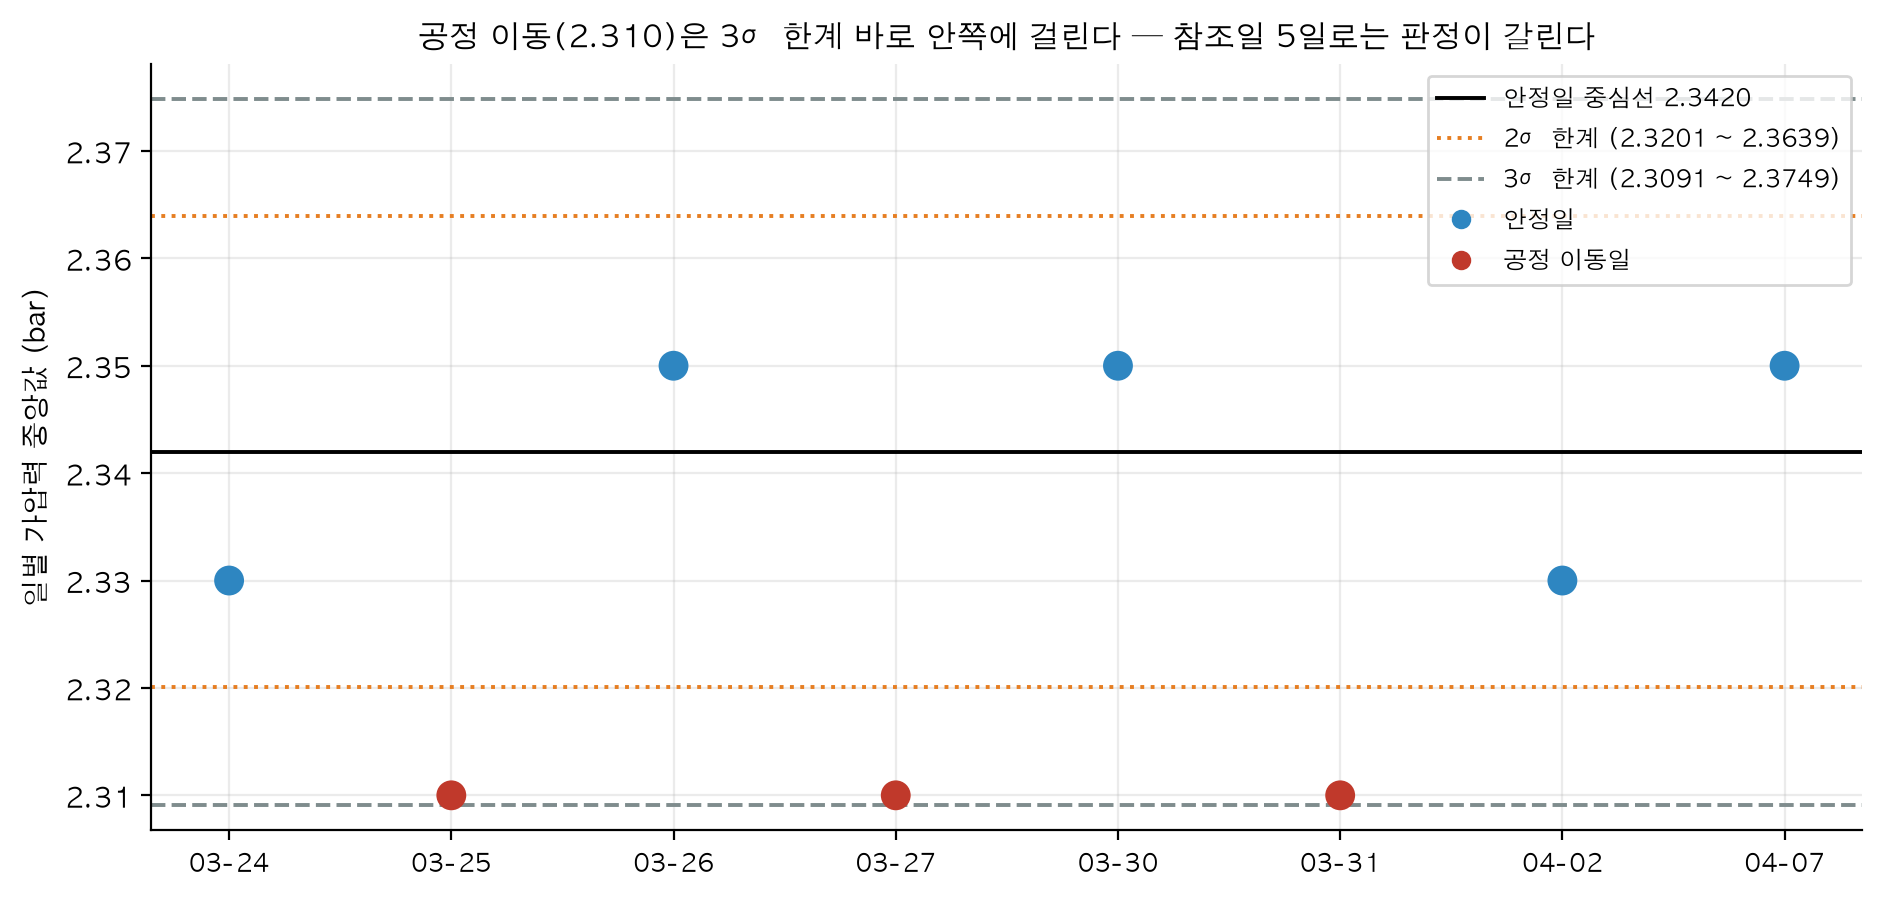

In [10]:
print("일 단위 관리도"); display(table("t55b_day_control_chart.csv"))
print("\n평가 대상 작업일의 정체"); display(table("t62_evaluated_days.csv"))
print("\n작업일 단위 정확 순열검정"); display(table("t59_day_level_permutation.csv"))
figure("f29_day_control_chart.png")

---
## 8. 왜 용접점 단위 예측을 제시하지 않았는가

관계를 **직접 심어놓고도** 복원되지 않는다는 것이 시뮬레이션의 요지다.
병목은 방법이 아니라 데이터다.

LLP 모델 비교


,모형,LOBO 개수 MAE,기준선 대비,예측 개수,실제 개수
0,M1 비율매칭 로지스틱,1.910,-12.2%,"3.6, 3.1, 6.0, 7.0, 2.7","4, 7, 4, 4, 3"
1,M0 전역 상수 (기준선),2.177,—,"4.2, 2.8, 5.4, 8.3, 2.2","4, 7, 4, 4, 3"
2,M3 평균사상(Mean Map),2.177,+0.0%,"4.2, 2.8, 5.4, 8.3, 2.2","4, 7, 4, 4, 3"
3,M2 교대 의사라벨,5.636,+158.9%,"6.2, 8.0, 16.2, 13.1, 6.5","4, 7, 4, 4, 3"



정확 순열검정 — 가방 5개의 분해능 한계


,모형,관측 MAE,배열 수,셔플 MAE 중앙값,셔플 MAE 최소,정확 순열 p,판정
0,M0 전역 상수 (기준선),2.177,20,2.260,0.622,0.45,우연과 구분 불가
1,M1 비율매칭 로지스틱,1.910,20,2.093,0.665,0.45,우연과 구분 불가
2,M2 교대 의사라벨,5.636,20,5.867,3.689,0.50,우연과 구분 불가
3,M3 평균사상(Mean Map),2.177,20,2.260,0.622,0.45,우연과 구분 불가



시뮬레이션 — 가방 수를 늘려도 복원되지 않는다


,오라클 AUC (심은 효과크기),가방 수,실현 오라클 AUC,M1 인스턴스 AUC,M1 표준편차,M3 인스턴스 AUC,M1 > 0.6 비율(%)
0,0.7,5,0.687,0.535,0.150,0.550,36.0
1,0.7,8,0.718,0.576,0.155,0.524,48.0
2,0.7,12,0.708,0.594,0.107,0.552,60.0
3,0.7,20,0.717,0.596,0.108,0.485,60.0
4,0.7,30,0.696,0.576,0.057,0.496,28.0
5,0.7,50,0.696,0.569,0.064,0.583,32.0
6,0.8,5,0.805,0.583,0.187,0.546,60.0
7,0.8,8,0.786,0.519,0.182,0.613,32.0
8,0.8,12,0.799,0.477,0.151,0.599,24.0
9,0.8,20,0.794,0.378,0.111,0.464,0.0


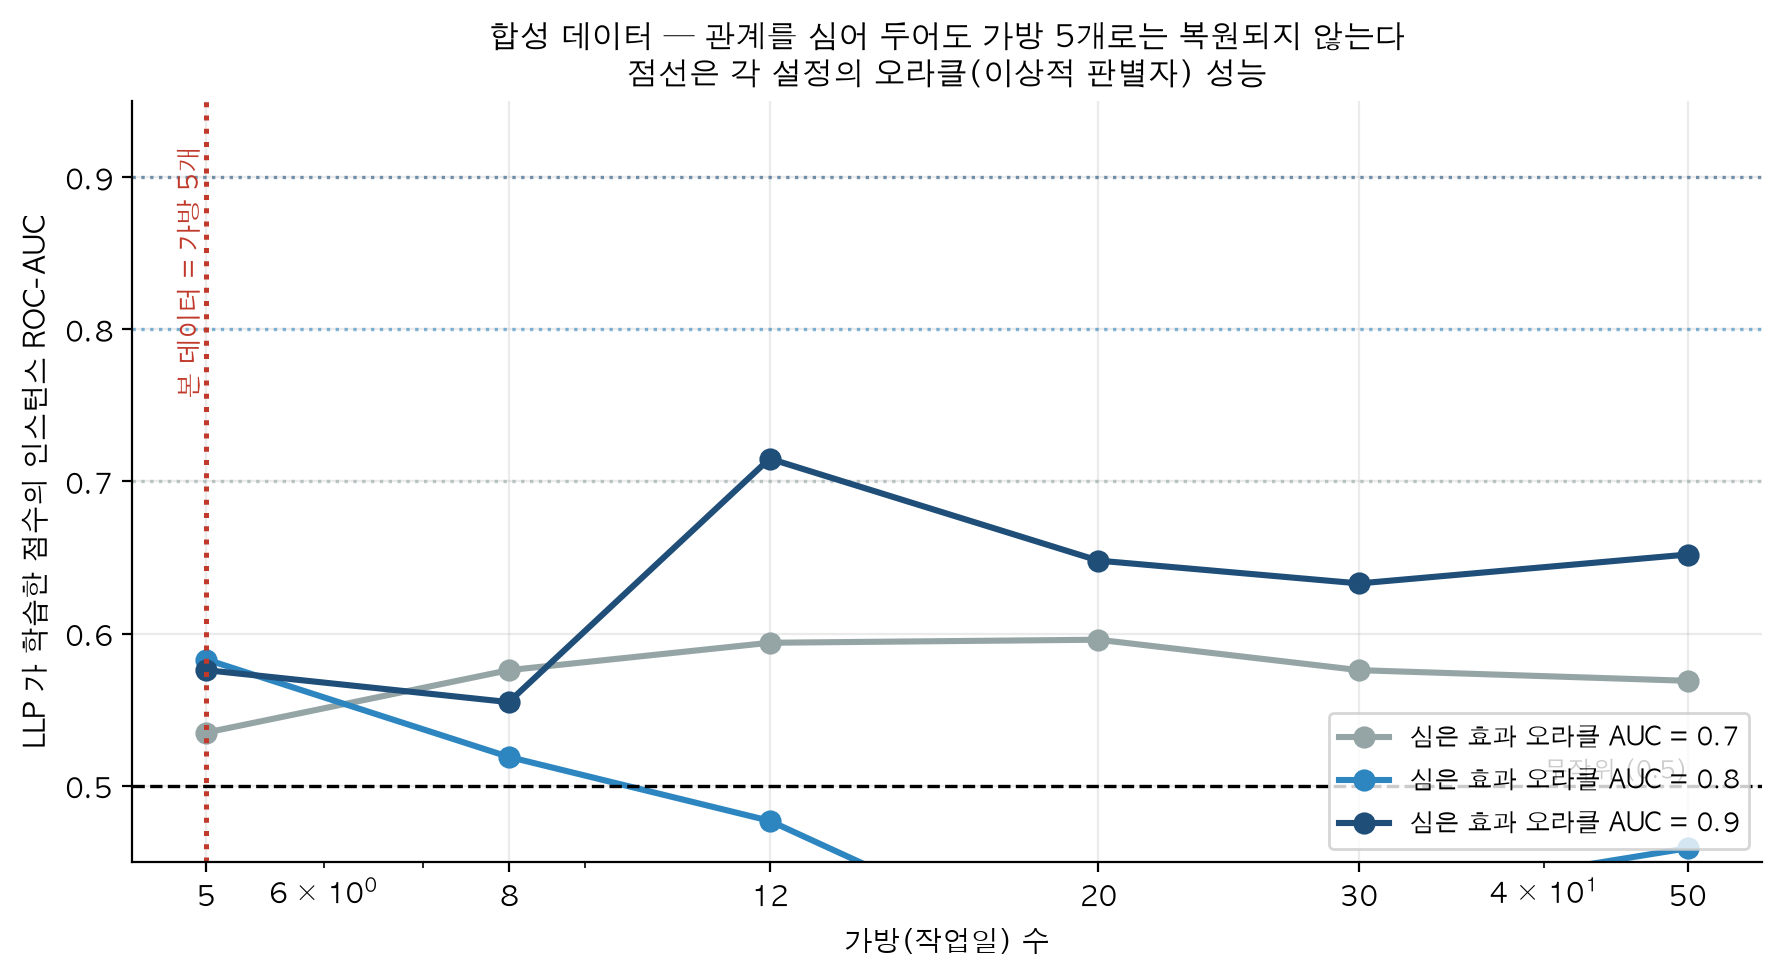

In [11]:
print("LLP 모델 비교"); display(table("t59_llp_comparison.csv"))
print("\n정확 순열검정 — 가방 5개의 분해능 한계"); display(table("t60_llp_permutation.csv"))
print("\n시뮬레이션 — 가방 수를 늘려도 복원되지 않는다"); display(table("t63_sim_bags.csv"))
figure("f32_simulation_bags.png")

### 전수 쓸이 (제출 후 추가)

사전지정 가설만으로는 "혹시 놓쳤는가"에 답할 수 없어, 일 단위 특징을 전수 생성해 검정했다.
**148건 중 다중검정 보정 전 기준으로도 유의 0건이다.**

,타깃,작업일 수,검정한 특징,최대 |rho|,그 특징,최소 순열 p,Bonferroni 임계,보정 전 p<0.05,보정 후 통과
0,용접부족,8,37,0.404,n__raw,0.3043,0.00135,0,0
1,크랙발생,7,37,0.463,cur_iqr__raw,0.3265,0.00135,0,0
2,파임불량,8,37,0.717,cur_std__raw,0.0550,0.00135,0,0
3,합계,8,37,0.583,force_cv__raw,0.1332,0.00135,0,0


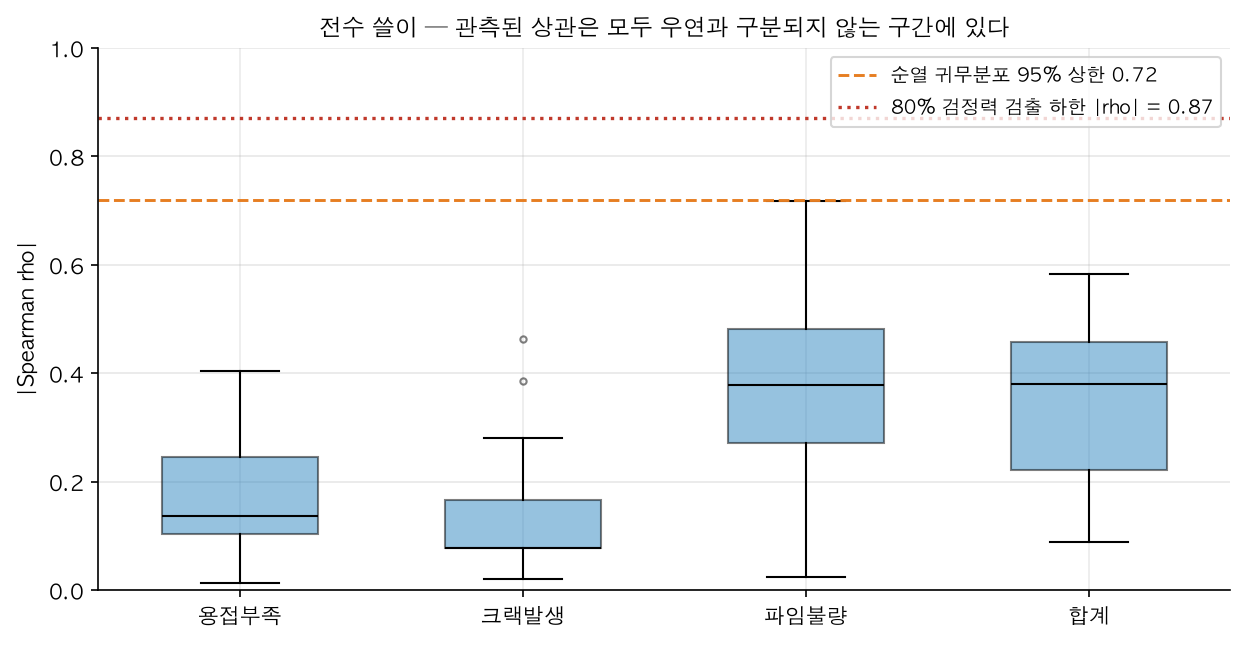

In [12]:
try:
    display(table("t71_sweep_summary.csv"))
    figure("f33_feature_sweep.png")
except FileNotFoundError:
    print("28_feature_sweep.py 를 실행하면 생성된다")

---
## 9. 산출물 진위 검사

파이프라인의 마지막 단계가 **보고서가 인용한 파일명을 본문에서 직접 추출**해
각 산출물의 생성시각과 SHA-256 을 검사한다. `STALE`·`MISSING` 이 있으면 **exit code 1** 이다.

In [13]:
import json
man = json.loads((ROOT / "outputs" / "run_manifest.json").read_text(encoding="utf-8"))
print("생성 시각 :", man["generated_at"])
print("검사 대상 :", man["cited_total"], "개")
print("상태      :", man["counts"])
print("판정      :", man["verdict"])
print("\n예시 — 해시가 기록된 산출물 3개")
for a in man["artifacts"][:3]:
    print(f"  {a['status']:8s} {a['file']:38s} {a['sha256'][:16]}...")

생성 시각 : 2026-10-08T12:12:58+0900
검사 대상 : 94 개
상태      : {'FRESH': 94}
판정      : PASS

예시 — 해시가 기록된 산출물 3개
  FRESH    t1_sheet_structure.csv                 5829288a8e23ac86...
  FRESH    t3_spec_vs_actual.csv                  db6c192721fb2786...
  FRESH    t2_label_reality.csv                   b5dfa08121cc2a6a...


---
## 한계

- **용접점별 실제 불량 라벨이 없다.** FN·FP·검출률을 계산하지 않았고 추정하지도 않았다.
- **현장 적용은 전부 시범운용 단계다.** 관리도의 σ 추정 자유도가 4라 2σ/3σ를 확정할 수 없다.
- **재검사 우선순위의 가치는 농축배수 r 에 달려 있다.** r 을 추정할 수 없어 절감액 대신
  손익분기 조건만 제시했다. r 은 현장이 플래그된 점만 1개월 재검사하면 측정된다.

자세한 내용은 [`report/결과보고서_본문.md`](../report/결과보고서_본문.md) 와
[`docs/PROGRESS.md`](../docs/PROGRESS.md) 를 참조.